# Unemployment Analysis with Python



In [ ]:
%matplotlib inline
import json, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

IN  = os.environ.get("IN_DIR", "./")
OUT = os.environ.get("OUT_DIR", "out/")
os.makedirs(OUT+"tables", exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.0)
C = {"base":"#2b6cb0","covid":"#e53e3e","rural":"#2f855a","urban":"#dd6b20","grey":"#718096"}
F = {}   # key findings, saved to json
def show_chart(name=None):
    """Display the current chart in the notebook instead of saving it to disk."""
    plt.tight_layout()
    plt.show()
    plt.close()


## LOAD & CLEAN

In [2]:
# 1. LOAD & CLEAN
d1 = pd.read_csv(r"c:\Users\HP\Downloads\Unemployment in India.csv")
d1.columns = ["State","Date","Freq","UR","Employed","LPR","Area"]
d2 = pd.read_csv(r"c:\Users\HP\Downloads\Unemployment_Rate_upto_11_2020.csv")
d2.columns = ["State","Date","Freq","UR","Employed","LPR","Zone","lat_raw","lon_raw"]

log = {"d1_raw_rows": len(d1), "d2_raw_rows": len(d2)}
log["d1_blank_rows_dropped"] = int(d1.isna().all(axis=1).sum())
d1 = d1.dropna(how="all").copy()

for df in (d1, d2):                                 
    for c in df.select_dtypes("object"): df[c] = df[c].str.strip()
    df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
    df["Freq"] = df["Freq"].replace({"M":"Monthly"})
d1["Area"] = d1["Area"].astype("category")

# the source file has latitude/longitude swapped (latitude column holds ~15.9 for A.P.)

d2 = d2.rename(columns={"lat_raw":"lon_fix","lon_raw":"lat_fix"})
d2["lat"], d2["lon"] = d2["lon_fix"], d2["lat_fix"]       
d2 = d2.drop(columns=["lon_fix","lat_fix"])
log["d1_duplicates"] = int(d1.duplicated().sum()); log["d2_duplicates"] = int(d2.duplicated().sum())
log["d1_zero_UR_rows"] = int((d1.UR==0).sum())          
log["d1_rows"], log["d2_rows"] = len(d1), len(d2)
log["d1_period"] = [str(d1.Date.min().date()), str(d1.Date.max().date())]
log["d2_period"] = [str(d2.Date.min().date()), str(d2.Date.max().date())]
log["d1_states"], log["d2_states"] = d1.State.nunique(), d2.State.nunique()
F["cleaning"] = log

# derived: labour force & unemployed persons (so national rates are population-weighted, not simple means)
for df in (d1, d2):
    df["LabourForce"] = df.Employed / (1 - df.UR/100)
    df["Unemployed"]  = df.LabourForce - df.Employed
def national(df, by="Date"):
    g = df.groupby(by).agg(Employed=("Employed","sum"), Unemployed=("Unemployed","sum"), LabourForce=("LabourForce","sum"),
                           LPR_mean=("LPR","mean"), UR_simple=("UR","mean"))
    g["UR"] = g.Unemployed / g.LabourForce * 100
    return g
nat1, nat2 = national(d1), national(d2)
nat1.to_csv(OUT+"tables/national_dataset1.csv"); nat2.to_csv(OUT+"tables/national_dataset2.csv")
d1.to_csv(OUT+"tables/cleaned_unemployment_in_india.csv", index=False)
d2.to_csv(OUT+"tables/cleaned_unemployment_2020.csv", index=False)

## EXPLORATION

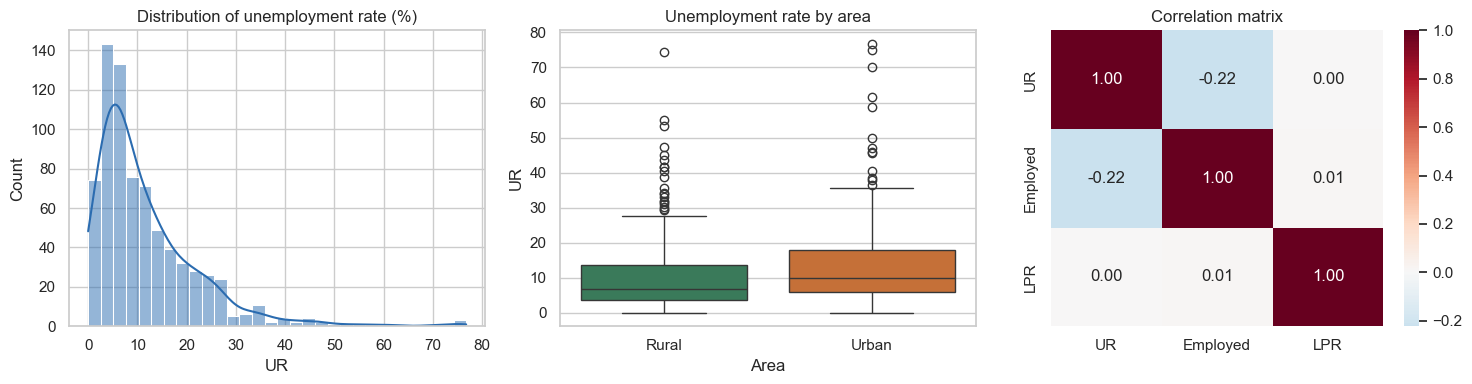

In [ ]:
#  2. EXPLORATION
F["describe_d1"] = d1[["UR","Employed","LPR"]].describe().round(2).to_dict()
F["corr_d1"] = d1[["UR","Employed","LPR"]].corr().round(3).to_dict()
F["corr_d2"] = d2[["UR","Employed","LPR"]].corr().round(3).to_dict()
F["skew_UR"] = round(float(d1.UR.skew()),2)

fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.histplot(d1.UR, bins=30, kde=True, ax=ax[0], color=C["base"]); ax[0].set_title("Distribution of unemployment rate (%)")
sns.boxplot(data=d1, x="Area", y="UR", ax=ax[1], palette=[C["rural"],C["urban"]]); ax[1].set_title("Unemployment rate by area")
sns.heatmap(d1[["UR","Employed","LPR"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[2]); ax[2].set_title("Correlation matrix")
show_chart("01_distribution_correlation")

## NATIONAL TREND (both datasets)

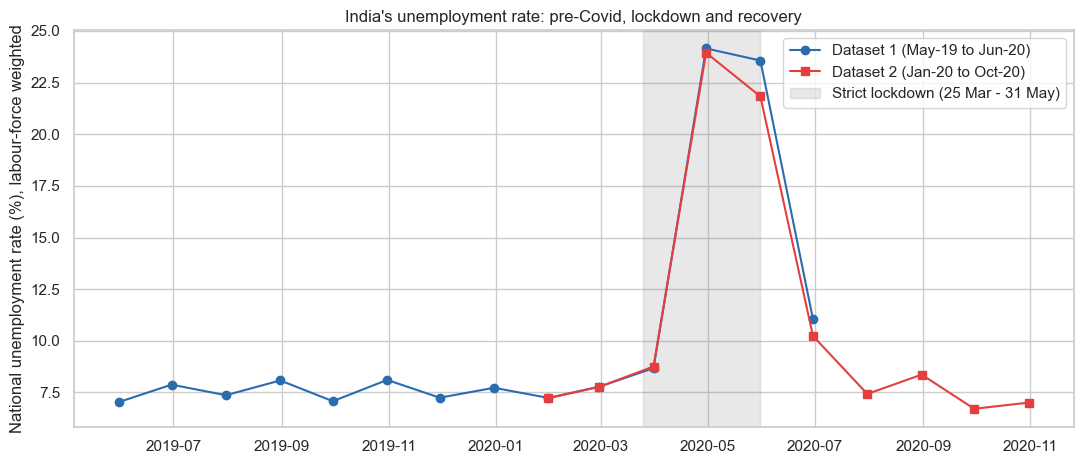

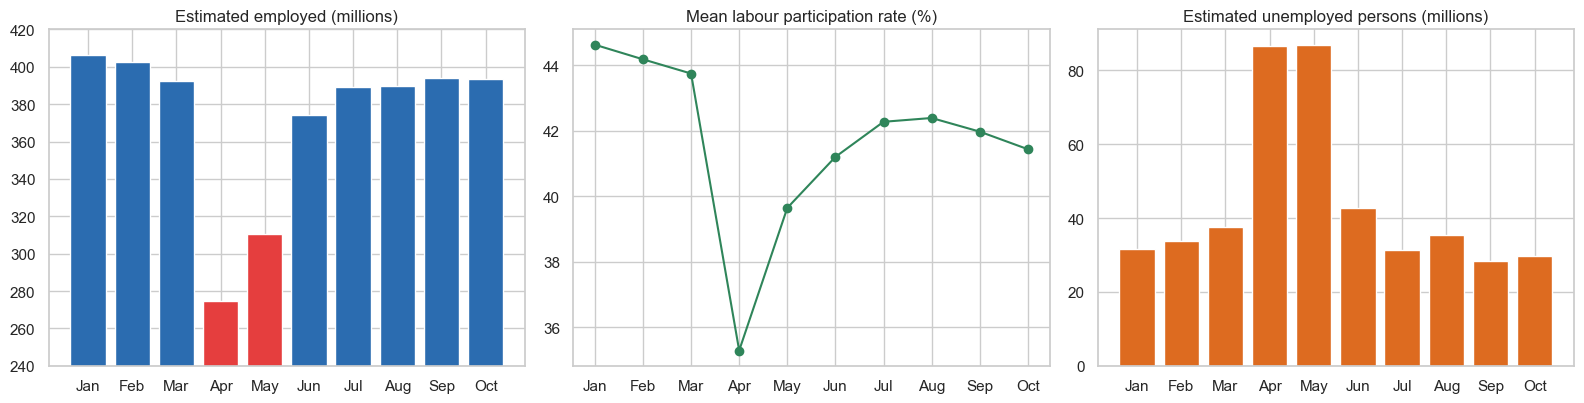

In [ ]:
# 3. NATIONAL TREND (both datasets)
fig, ax = plt.subplots(figsize=(11,4.8))
ax.plot(nat1.index, nat1.UR, marker="o", color=C["base"], label="Dataset 1 (May-19 to Jun-20)")
ax.plot(nat2.index, nat2.UR, marker="s", color=C["covid"], label="Dataset 2 (Jan-20 to Oct-20)")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="grey", alpha=.18, label="Strict lockdown (25 Mar - 31 May)")
ax.set_ylabel("National unemployment rate (%), labour-force weighted"); ax.set_title("India's unemployment rate: pre-Covid, lockdown and recovery"); ax.legend()
show_chart("02_national_trend")

pre1 = nat1.loc[:"2020-03-31"]; 
base = nat1.loc["2019-05-31":"2020-02-29"].UR.mean()
pk = nat2.UR.idxmax()
F["national"] = {
 "pre_covid_mean_UR_May19_Feb20": round(base,2),
 "UR_Mar20": round(nat2.loc["2020-03-31","UR"],2), "UR_Apr20": round(nat2.loc["2020-04-30","UR"],2),
 "UR_May20": round(nat2.loc["2020-05-31","UR"],2), "UR_Jun20": round(nat2.loc["2020-06-30","UR"],2),
 "UR_Oct20": round(nat2.loc["2020-10-31","UR"],2), "peak_month": str(pk.date()), "peak_UR": round(nat2.UR.max(),2),
 "Employed_Feb20_M": round(nat2.loc["2020-02-29","Employed"]/1e6,1), "Employed_Apr20_M": round(nat2.loc["2020-04-30","Employed"]/1e6,1),
 "Employed_Oct20_M": round(nat2.loc["2020-10-31","Employed"]/1e6,1),
 "LPR_Feb20": round(nat2.loc["2020-02-29","LPR_mean"],2), "LPR_Apr20": round(nat2.loc["2020-04-30","LPR_mean"],2),
 "LPR_Oct20": round(nat2.loc["2020-10-31","LPR_mean"],2),
 "Unemployed_Feb20_M": round(nat2.loc["2020-02-29","Unemployed"]/1e6,1), "Unemployed_Apr20_M": round(nat2.loc["2020-04-30","Unemployed"]/1e6,1),
 "Unemployed_May20_M": round(nat2.loc["2020-05-31","Unemployed"]/1e6,1), "Unemployed_Oct20_M": round(nat2.loc["2020-10-31","Unemployed"]/1e6,1),
 "LabourForce_Feb20_M": round(nat2.loc["2020-02-29","LabourForce"]/1e6,1), "LabourForce_Oct20_M": round(nat2.loc["2020-10-31","LabourForce"]/1e6,1),
}
n = F["national"]
n["jobs_lost_Feb_to_Apr_M"] = round(n["Employed_Feb20_M"]-n["Employed_Apr20_M"],1)
n["jobs_lost_pct"] = round(n["jobs_lost_Feb_to_Apr_M"]/n["Employed_Feb20_M"]*100,1)
n["employment_recovered_pct_of_Feb_by_Oct"] = round(n["Employed_Oct20_M"]/n["Employed_Feb20_M"]*100,1)
n["UR_Oct_vs_pre_covid_pp"] = round(n["UR_Oct20"]-nat2.loc["2020-01-31":"2020-02-29","UR"].mean(),2)

# jobs, labour force, participation
fig, ax = plt.subplots(1,3, figsize=(16,4.2))
ax[0].bar(nat2.index.strftime("%b"), nat2.Employed/1e6, color=[C["covid"] if m in (4,5) else C["base"] for m in nat2.index.month]); ax[0].set_title("Estimated employed (millions)")
ax[0].set_ylim(240, 420)
ax[1].plot(nat2.index.strftime("%b"), nat2.LPR_mean, marker="o", color=C["rural"]); ax[1].set_title("Mean labour participation rate (%)")
ax[2].bar(nat2.index.strftime("%b"), nat2.Unemployed/1e6, color=C["urban"]); ax[2].set_title("Estimated unemployed persons (millions)")
show_chart("03_employment_lfpr_unemployed")

## COVID IMPACT

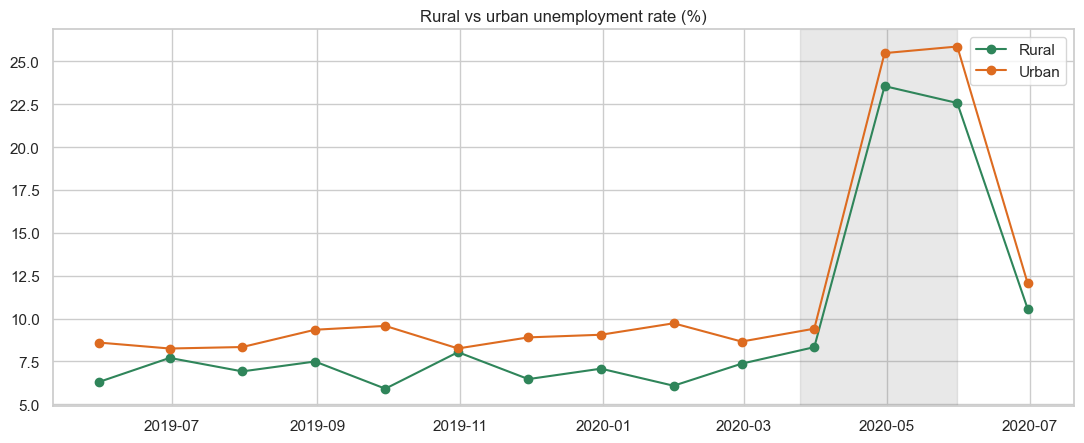

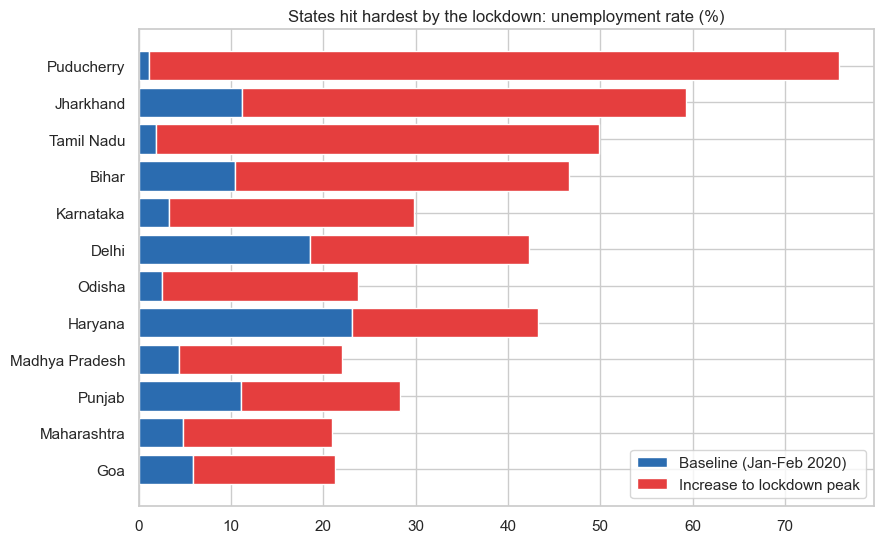

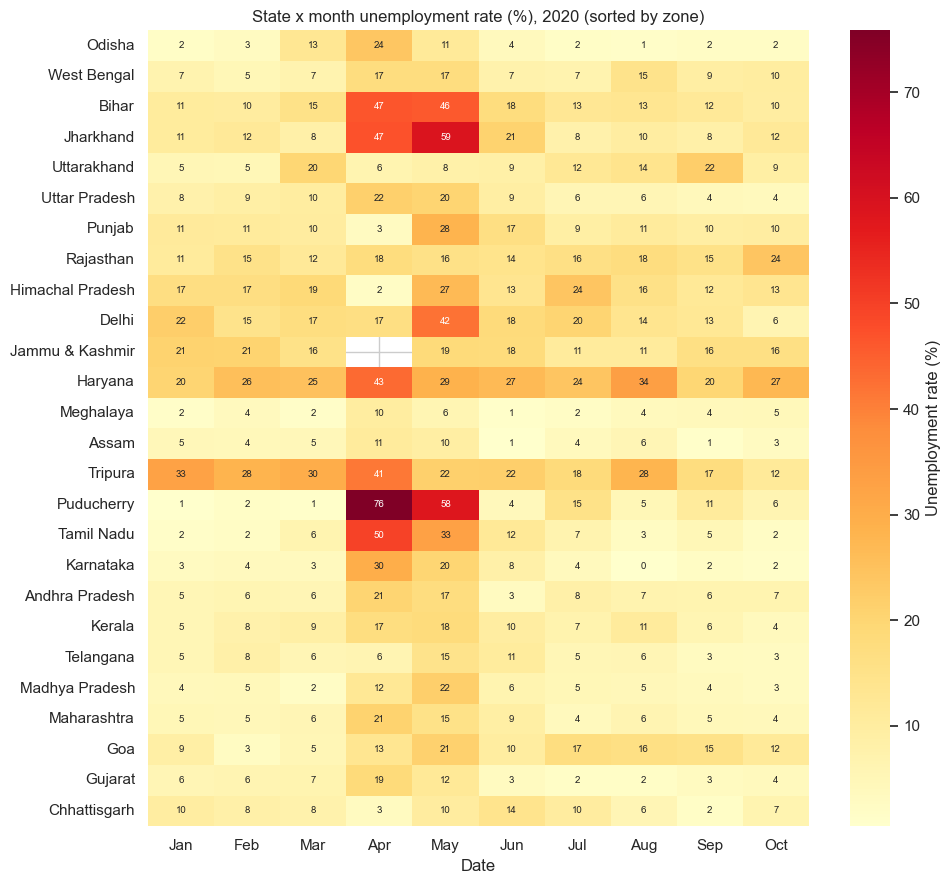

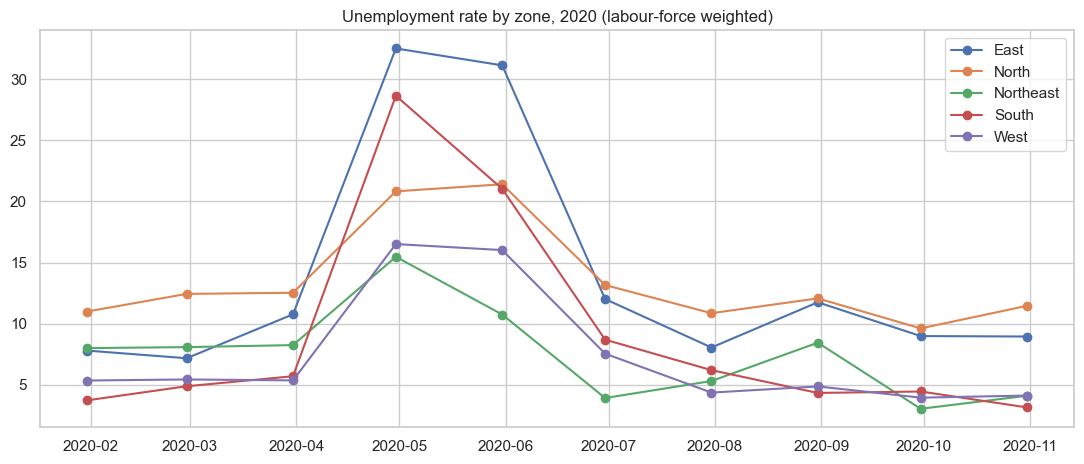

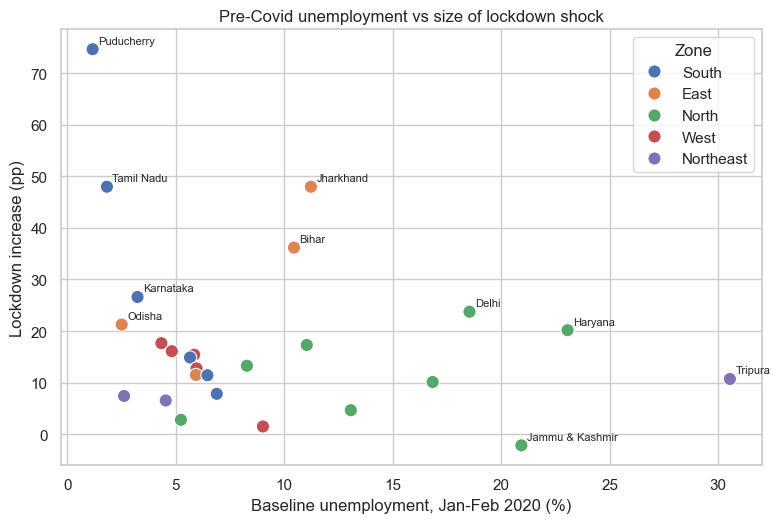

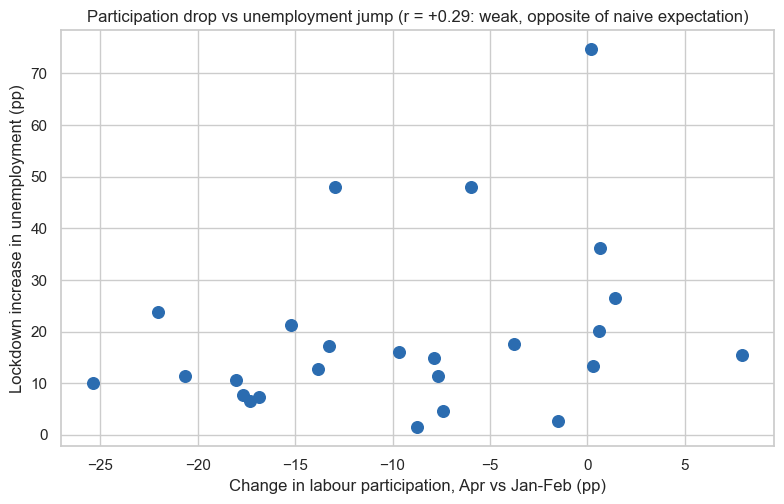

In [ ]:
# 4. COVID IMPACT
def phase(dt):
    if dt < pd.Timestamp("2020-03-25"): return "1 Pre-Covid"
    if dt <= pd.Timestamp("2020-05-31"): return "2 Lockdown"
    return "3 Recovery"
d1["Phase"] = d1.Date.map(phase); d2["Phase"] = d2.Date.map(phase)
# note: March-20 is month-end so the date maps to 'Lockdown'; use month-based phases instead
def phase_m(dt):
    return "1 Pre-Covid" if dt <= pd.Timestamp("2020-03-31") else ("2 Lockdown" if dt <= pd.Timestamp("2020-05-31") else "3 Recovery")
d1["Phase"] = d1.Date.map(phase_m); d2["Phase"] = d2.Date.map(phase_m)

# 4a. Rural vs urban (dataset 1)
ru = d1.groupby(["Date","Area"]).apply(lambda g: g.Unemployed.sum()/g.LabourForce.sum()*100).unstack()
ru.to_csv(OUT+"tables/rural_urban_national.csv")
fig, ax = plt.subplots(figsize=(11,4.6))
ax.plot(ru.index, ru.Rural, marker="o", color=C["rural"], label="Rural"); ax.plot(ru.index, ru.Urban, marker="o", color=C["urban"], label="Urban")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-05-31"), color="grey", alpha=.18)
ax.set_title("Rural vs urban unemployment rate (%)"); ax.legend(); show_chart("04_rural_vs_urban")
pre_ru = ru.loc[:"2020-03-31"].mean()
F["rural_urban"] = {"pre_covid_mean": pre_ru.round(2).to_dict(), "Apr20": ru.loc["2020-04-30"].round(2).to_dict(),
  "May20": ru.loc["2020-05-31"].round(2).to_dict(), "Jun20": ru.loc["2020-06-30"].round(2).to_dict(),
  "urban_gap_pre_pp": round(pre_ru.Urban-pre_ru.Rural,2), "urban_gap_May_pp": round(ru.loc["2020-05-31","Urban"]-ru.loc["2020-05-31","Rural"],2)}
pre_piv = d1[d1.Phase=="1 Pre-Covid"].pivot_table(index=["State","Date"], columns="Area", values="UR").dropna()
t,p = stats.ttest_rel(pre_piv.Urban, pre_piv.Rural)
F["rural_urban"]["paired_t_pre_covid"] = {"t":round(t,2),"p":float(f"{p:.2e}")}

# 4b. State-level shock (dataset 2 = broader; baseline = Jan-Feb 2020)
st = d2.pivot_table(index="State", columns="Date", values="UR")
st.columns = st.columns.strftime("%b")
zone = d2.groupby("State").Zone.first()
base_s = st[["Jan","Feb"]].mean(axis=1)
peak_s = st[["Apr","May"]].max(axis=1)
peak_m = st[["Apr","May"]].idxmax(axis=1)
oct_s = st["Oct"]
sm = pd.DataFrame({"Zone":zone,"Baseline_JanFeb":base_s,"Apr":st["Apr"],"May":st["May"],"Peak":peak_s,"PeakMonth":peak_m,"Oct":oct_s})
F["excluded_from_shock_stats"] = sm[sm.Baseline_JanFeb.isna()].index.tolist()   # Sikkim: no Jan/Feb 2020 readings
sm = sm.dropna(subset=["Baseline_JanFeb"])            # J&K has no April reading -> its peak uses May (skipna max)
sm["Shock_pp"] = sm.Peak-sm.Baseline_JanFeb
sm["Oct_vs_Base_pp"] = sm.Oct-sm.Baseline_JanFeb
# months after the peak month until UR <= baseline + 2pp (stays there through Oct)
def recov(r):
    s = st.loc[r.name, ["Jun","Jul","Aug","Sep","Oct"]]
    ok = (s <= r.Baseline_JanFeb + 2)
    for i,m in enumerate(s.index):
        if ok[i:].all(): return m
    return "Not yet"
sm["Recovered_by"] = sm.apply(recov, axis=1)
sm = sm.sort_values("Shock_pp", ascending=False).round(2); sm.to_csv(OUT+"tables/state_covid_shock.csv")
F["state_shock"] = {"top5_increase": sm.head(5)[["Peak","Shock_pp"]].to_dict("index"),
  "lowest5_increase": sm.tail(5)[["Peak","Shock_pp"]].to_dict("index"),
  "n_states_above_20pct_peak": int((sm.Peak>20).sum()),
  "n_not_recovered_Oct": int((sm.Recovered_by=="Not yet").sum()), "not_recovered": sm[sm.Recovered_by=="Not yet"].index.tolist(),
  "n_above_base_by_2pp_Oct": int((sm.Oct_vs_Base_pp>2).sum()),
  "worse_than_base_Oct": sm[sm.Oct_vs_Base_pp>0].index.tolist(), "better_than_base_Oct": sm[sm.Oct_vs_Base_pp<0].index.tolist(),
  "peak_month_counts": sm.PeakMonth.value_counts().to_dict()}

top = sm.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9,5.6))
ax.barh(top.index, top.Baseline_JanFeb, color=C["base"], label="Baseline (Jan-Feb 2020)")
ax.barh(top.index, top.Shock_pp, left=top.Baseline_JanFeb, color=C["covid"], label="Increase to lockdown peak")
ax.set_title("States hit hardest by the lockdown: unemployment rate (%)"); ax.legend(loc="lower right"); show_chart("05_top_states_shock")

mo = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct"]
order = sm.sort_values(["Zone","Baseline_JanFeb"]).index
fig, ax = plt.subplots(figsize=(10,9))
sns.heatmap(st.loc[order, mo], cmap="YlOrRd", annot=True, fmt=".0f", annot_kws={"size":7}, cbar_kws={"label":"Unemployment rate (%)"}, ax=ax)
ax.set_title("State x month unemployment rate (%), 2020 (sorted by zone)"); ax.set_ylabel(""); show_chart("06_state_month_heatmap")

# 4c. Zone view
zm = d2.groupby(["Zone","Date"]).apply(lambda g: g.Unemployed.sum()/g.LabourForce.sum()*100).unstack(0)
zm.to_csv(OUT+"tables/zone_monthly_UR.csv")
fig, ax = plt.subplots(figsize=(11,4.8))
for z in zm.columns: ax.plot(zm.index, zm[z], marker="o", label=z)
ax.set_title("Unemployment rate by zone, 2020 (labour-force weighted)"); ax.legend(); show_chart("07_zone_trend")
F["zone"] = {"Apr": zm.loc["2020-04-30"].round(1).to_dict(), "May": zm.loc["2020-05-31"].round(1).to_dict(),
             "Feb": zm.loc["2020-02-29"].round(1).to_dict(), "Oct": zm.loc["2020-10-31"].round(1).to_dict()}
shock_by_zone = sm.groupby("Zone").Shock_pp.apply(list)
f,p = stats.f_oneway(*shock_by_zone.values)
F["zone"]["anova_shock_by_zone"] = {"F":round(f,2),"p":round(float(p),4)}
F["zone"]["mean_shock_pp"] = sm.groupby("Zone").Shock_pp.mean().round(1).to_dict()

# 4d. Statistical test: did the lockdown change things? (state-level, paired)
pre_state = d2[d2.Date<=pd.Timestamp("2020-02-29")].groupby("State").UR.mean()
lock_state = d2[d2.Date.isin(pd.to_datetime(["2020-04-30","2020-05-31"]))].groupby("State").UR.mean()
w = stats.wilcoxon(lock_state.loc[pre_state.index], pre_state)
F["wilcoxon_pre_vs_lockdown"] = {"stat":float(w.statistic), "p":float(f"{w.pvalue:.2e}")}

# 4e. Does a high pre-covid rate predict a bigger shock? (structural vs shock)
r,p = stats.spearmanr(sm.Baseline_JanFeb, sm.Shock_pp)
F["baseline_vs_shock_spearman"] = {"rho":round(r,2),"p":round(p,3)}
fig, ax = plt.subplots(figsize=(8,5.4))
sns.scatterplot(data=sm, x="Baseline_JanFeb", y="Shock_pp", hue="Zone", s=90, ax=ax)
for s_,r_ in sm.iterrows():
    if r_.Shock_pp>20 or r_.Baseline_JanFeb>20: ax.annotate(s_, (r_.Baseline_JanFeb, r_.Shock_pp), fontsize=8, xytext=(4,4), textcoords="offset points")
ax.set_xlabel("Baseline unemployment, Jan-Feb 2020 (%)"); ax.set_ylabel("Lockdown increase (pp)"); ax.set_title("Pre-Covid unemployment vs size of lockdown shock"); show_chart("08_baseline_vs_shock")

# 4f. Participation: discouraged workers
lp = d2.pivot_table(index="State", columns="Date", values="LPR"); lp.columns = lp.columns.strftime("%b")
lp_drop = (lp["Apr"]-lp[["Jan","Feb"]].mean(axis=1)).reindex(sm.index).dropna()
lp_oct  = (lp["Oct"]-lp[["Jan","Feb"]].mean(axis=1)).reindex(sm.index).dropna()
F["participation"] = {"mean_drop_Apr_pp": round(lp_drop.mean(),2), "mean_change_Oct_vs_JanFeb_pp": round(lp_oct.mean(),2),
   "states_LPR_below_base_Oct": int((lp_oct<0).sum()), "n_states": len(lp_oct),
   "biggest_LPR_drop_Apr": lp_drop.sort_values().head(5).round(1).to_dict()}
fig, ax = plt.subplots(figsize=(8,5.2))
ax.scatter(lp_drop, sm.loc[lp_drop.index,"Shock_pp"], s=70, color=C["base"])
ax.set_xlabel("Change in labour participation, Apr vs Jan-Feb (pp)"); ax.set_ylabel("Lockdown increase in unemployment (pp)")
ax.set_title("Participation drop vs unemployment jump (r = +0.29: weak, opposite of naive expectation)"); show_chart("09_participation_vs_shock")
F["participation"]["corr_LPRdrop_vs_shock"] = round(float(np.corrcoef(lp_drop, sm.loc[lp_drop.index,"Shock_pp"])[0,1]),2)

## SEASONALITY / PATTERNS

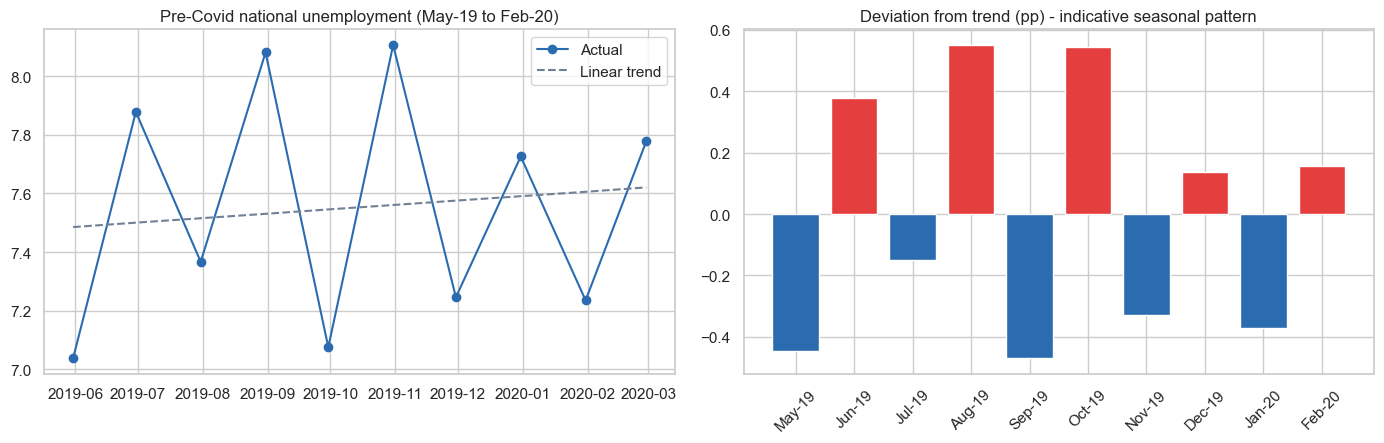

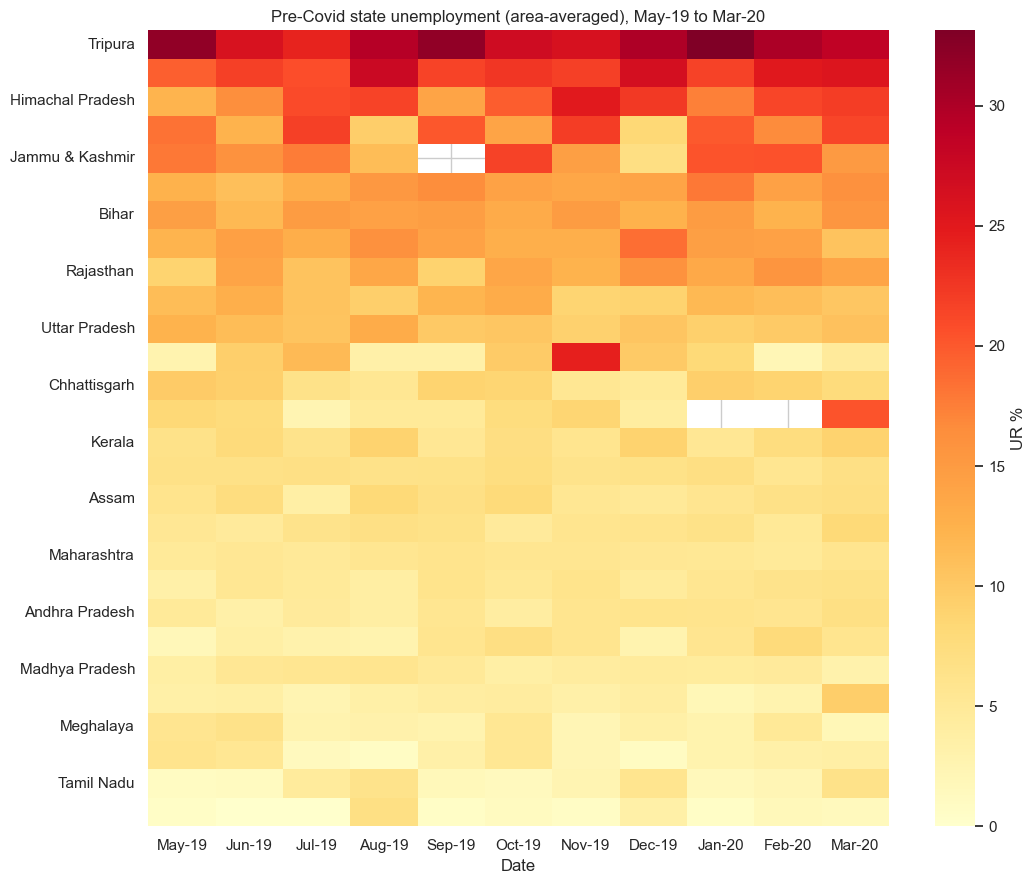

In [6]:
#5. SEASONALITY / PATTERNS

pre = nat1.loc["2019-05-31":"2020-02-29"].copy()
pre["trend"] = np.polyval(np.polyfit(np.arange(len(pre)), pre.UR, 1), np.arange(len(pre)))
pre["detrended"] = pre.UR - pre.trend
slope = np.polyfit(np.arange(len(pre)), pre.UR, 1)[0]
F["seasonality"] = {"pre_covid_trend_pp_per_month": round(slope,3),
   "highest_months": pre.UR.sort_values(ascending=False).head(3).round(2).rename(lambda x:x.strftime("%b-%y")).to_dict(),
   "lowest_months": pre.UR.sort_values().head(3).round(2).rename(lambda x:x.strftime("%b-%y")).to_dict(),
   "detrended_by_month": pre.detrended.round(2).rename(lambda x:x.strftime("%b-%y")).to_dict(),
   "pre_UR_range_pp": round(pre.UR.max()-pre.UR.min(),2)}
rur = ru.loc["2019-05-31":"2020-02-29"]
F["seasonality"]["rural_range"] = [round(rur.Rural.min(),2), round(rur.Rural.max(),2)]
F["seasonality"]["urban_range"] = [round(rur.Urban.min(),2), round(rur.Urban.max(),2)]
F["seasonality"]["rural_peak_month"] = rur.Rural.idxmax().strftime("%b-%y"); F["seasonality"]["rural_low_month"] = rur.Rural.idxmin().strftime("%b-%y")
fig, ax = plt.subplots(1,2, figsize=(14,4.6))
ax[0].plot(pre.index, pre.UR, marker="o", color=C["base"], label="Actual"); ax[0].plot(pre.index, pre.trend, "--", color=C["grey"], label="Linear trend")
ax[0].set_title("Pre-Covid national unemployment (May-19 to Feb-20)"); ax[0].legend()
ax[1].bar(pre.index.strftime("%b-%y"), pre.detrended, color=np.where(pre.detrended>0, C["covid"], C["base"])); ax[1].set_title("Deviation from trend (pp) - indicative seasonal pattern")
plt.setp(ax[1].get_xticklabels(), rotation=45); show_chart("10_pre_covid_seasonality")

# seasonal-ish regularity across states: volatility before Covid, rural vs urban
vol = d1[d1.Phase=="1 Pre-Covid"].groupby(["State","Area"]).UR.std().unstack()
vol["Mean_UR"] = d1[d1.Phase=="1 Pre-Covid"].groupby("State").UR.mean()
vol = vol.round(2).sort_values("Mean_UR", ascending=False); vol.to_csv(OUT+"tables/state_prekovid_volatility.csv")
F["volatility"] = {"most_volatile_rural": vol.Rural.sort_values(ascending=False).head(3).to_dict(), "most_volatile_urban": vol.Urban.sort_values(ascending=False).head(3).to_dict()}
fig, ax = plt.subplots(figsize=(11,4.8))
pv = d1[d1.Phase=="1 Pre-Covid"].pivot_table(index="State", columns=d1.Date.dt.strftime("%b-%y"), values="UR")
pv = pv[sorted(pv.columns, key=lambda s: pd.to_datetime(s, format="%b-%y"))]
sns.heatmap(pv.loc[pv.mean(axis=1).sort_values(ascending=False).index], cmap="YlOrRd", ax=ax, cbar_kws={"label":"UR %"}); ax.set_title("Pre-Covid state unemployment (area-averaged), May-19 to Mar-20"); ax.set_ylabel("")
fig.set_size_inches(11,9); show_chart("11_precovid_state_heatmap")

## STRUCTURAL RANKING (preCovid)

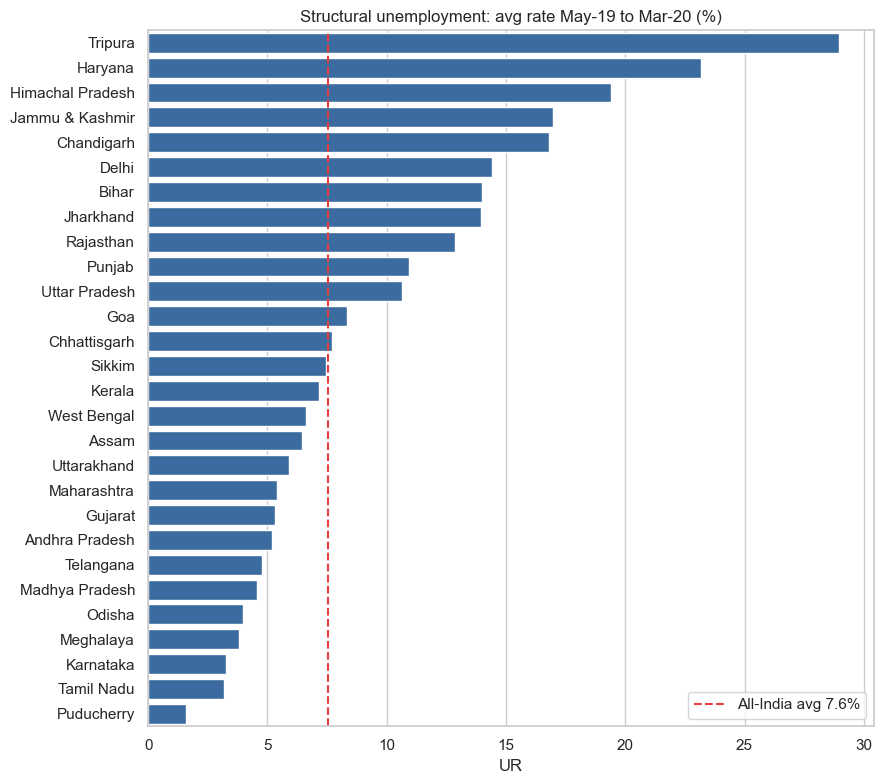

In [ ]:
# 6. STRUCTURAL RANKING (pre-Covid)
rank = d1[d1.Phase=="1 Pre-Covid"].groupby("State").agg(UR=("UR","mean"), LPR=("LPR","mean")).sort_values("UR", ascending=False).round(2)
rank.to_csv(OUT+"tables/state_precovid_ranking.csv")
F["structural"] = {"highest5": rank.head(5).UR.to_dict(), "lowest5": rank.tail(5).UR.to_dict()}
fig, ax = plt.subplots(figsize=(9,8))
sns.barplot(x=rank.UR, y=rank.index, color=C["base"], ax=ax); ax.axvline(base, color=C["covid"], ls="--", label=f"All-India avg {base:.1f}%"); ax.legend()
ax.set_title("Structural unemployment: avg rate May-19 to Mar-20 (%)"); ax.set_ylabel(""); show_chart("12_structural_ranking")

# Employment vs participation relation (cross-section, pre-Covid)
F["lpr_vs_ur_pre_spearman"] = dict(zip(["rho","p"], [round(x,3) for x in stats.spearmanr(rank.LPR, rank.UR)]))

## CLUSTERING: state profiles

In [ ]:
# 7. CLUSTERING: state profiles
feat = sm[["Baseline_JanFeb","Shock_pp","Oct_vs_Base_pp"]].copy()
feat["LPR_drop"] = lp_drop
feat = feat.dropna()   # J&K has no April LPR
X = StandardScaler().fit_transform(feat)
km = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X)
feat["Cluster"] = km.labels_
cm = feat.groupby("Cluster").mean().round(1); cm["n_states"] = feat.Cluster.value_counts().sort_index()
cm["states"] = feat.groupby("Cluster").apply(lambda g: ", ".join(g.index))
cm.to_csv(OUT+"tables/state_clusters.csv"); feat.to_csv(OUT+"tables/state_cluster_membership.csv")
F["clusters"] = cm.to_dict("index")
fig, ax = plt.subplots(figsize=(8.5,5.6))
sns.scatterplot(data=feat, x="Baseline_JanFeb", y="Shock_pp", hue="Cluster", palette="Set1", s=110, ax=ax)
for s_,r_ in feat.iterrows():
    if r_.Shock_pp>25 or r_.Baseline_JanFeb>18: ax.annotate(s_, (r_.Baseline_JanFeb, r_.Shock_pp), fontsize=8, xytext=(4,4), textcoords="offset points")
ax.set_title("State clusters: baseline vs lockdown shock"); show_chart("13_state_clusters")

## GEOGRAPHY (bubble map using lat/lon)

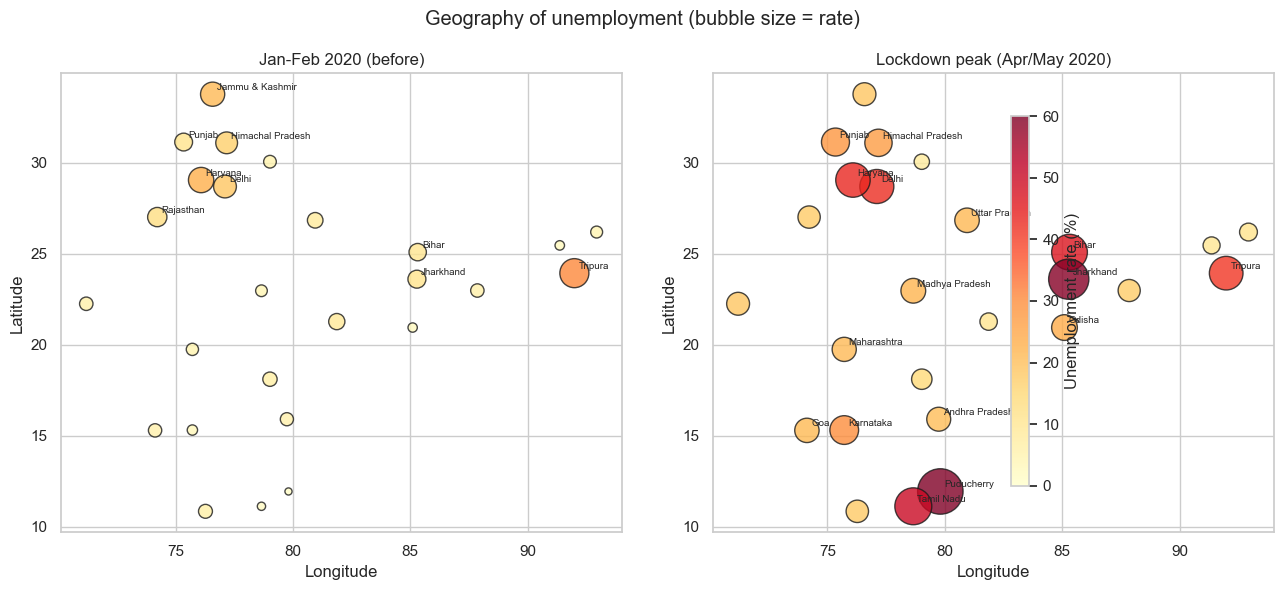

In [8]:
# 8. GEOGRAPHY (bubble map using lat/lon)
g = d2.merge(sm[["Peak"]], left_on="State", right_index=True).drop_duplicates("State")
fig, axs = plt.subplots(1,2, figsize=(13,6))
for a_, col, t in [(axs[0], "Baseline_JanFeb", "Jan-Feb 2020 (before)"), (axs[1], "Peak", "Lockdown peak (Apr/May 2020)")]:
    vals = sm.loc[g.State, col].values
    sc = a_.scatter(g.lon, g.lat, s=vals*14+10, c=vals, cmap="YlOrRd", vmin=0, vmax=60, edgecolor="k", alpha=.8)
    a_.set_title(t); a_.set_xlabel("Longitude"); a_.set_ylabel("Latitude")
    for _,r_ in g.iterrows():
        if sm.loc[r_.State, col] > (20 if col=="Peak" else 10): a_.annotate(r_.State, (r_.lon, r_.lat), fontsize=7, xytext=(3,3), textcoords="offset points")
plt.colorbar(sc, ax=axs, label="Unemployment rate (%)", shrink=.8); plt.suptitle("Geography of unemployment (bubble size = rate)")
plt.tight_layout(); plt.show(); plt.close()

## DATASET 1 vs 2 CONSISTENCY (overlap JanJun 2020)

In [ ]:
# 9. DATASET 1 vs 2 CONSISTENCY (overlap Jan-Jun 2020)
ov = pd.concat([nat1.UR.loc["2020-01-31":"2020-06-30"].rename("Dataset1"), nat2.UR.loc["2020-01-31":"2020-06-30"].rename("Dataset2")], axis=1).round(2)
ov.to_csv(OUT+"tables/overlap_check.csv"); F["overlap_check"] = ov.rename(lambda x:x.strftime("%b-%y")).to_dict()
F["overlap_corr"] = round(float(ov.corr().iloc[0,1]),3)